Ce notebook presente le modele RF classifier pour la variable cible 'TousAge_allergie_urgences'

In [1]:
import pandas as pd
import numpy as np

Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")

Merge_final.info()

Merge_final.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 81 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

C:\Users\gauxm\AppData\Local\Temp\ipykernel_31008\2492055701.py:4: DtypeWarning: Columns (1: code_dept) have mixed types. Specify dtype option on import or set low_memory=False.
  Merge_final = pd.read_csv("../data/final_metropole/Merge_final_2.csv")


,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,False


In [2]:
#Suppression colonnes
Merge_final_FS_MLA = Merge_final.drop(columns=[
    '0an_bronchiolite_urgences', 
    '65plus_allergie_urgences',
    '0_14_allergie_urgences',
    '15_64_allergie_urgences',
    '0_14_asthme_urgences',
    '15_64_asthme_urgences',
    'TousAge_asthme_urgences',
    '65plus_asthme_urgences',
    '0an_bronchiolite_hospitalisation',
    'TousAge_allergie_hospitalisation',
    '65plus_allergie_hospitalisation',
    '0_14_allergie_hospitalisation',
    '15_64_allergie_hospitalisation',
    '0_14_asthme_hospitalisation',
    '15_64_asthme_hospitalisation',
    'TousAge_asthme_hospitalisation',
    '65plus_asthme_hospitalisation',
    'Ntop_Maladie_Respi_Chronique_tsage_9',
    'Npop_Maladie_Respi_Chronique_tsage_9',
    'Ntop_Maladie_Respi_Chronique_0-14_9',
    'Ntop_Maladie_Respi_Chronique_15-64_9',
    'Ntop_Maladie_Respi_Chronique_65+_9',
    'Npop_Maladie_Respi_Chronique_0-14_9',
    'Npop_Maladie_Respi_Chronique_15-64_9',
    'Npop_Maladie_Respi_Chronique_65+_9',
    'nom_dep',])

Merge_final_FS_MLA.info()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  object 
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

In [3]:
#Met dans le bon type les variables

Merge_final_FS_MLA["code_dept"] = Merge_final_FS_MLA["code_dept"].astype("str")

Merge_final_FS_MLA['sos_present'] = Merge_final_FS_MLA['sos_present'].astype(int)

Merge_final_FS_MLA.info()

Merge_final_FS_MLA.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 55 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_ouvriers,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present
0,2021-S01,01,0.326250,0.610000,0.0500,0.4225,0.002025,16.272727,20.909091,19.363636,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
1,2021-S02,01,0.491563,1.065833,0.1375,3.0825,0.005350,22.257143,27.214286,13.928571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
2,2021-S03,01,0.581875,0.396667,0.0800,5.8525,0.008425,14.635714,50.714286,8.214286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
3,2021-S04,01,0.399687,0.385833,0.0900,3.4125,0.006250,21.864286,34.071429,11.428571,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0
4,2021-S05,01,0.390000,0.360833,0.0850,1.2350,0.004900,21.028571,30.428571,15.714286,...,14.2,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0


Étape 1 : Préparation du DataFrame & Découpage Temporel

In [4]:
# Copie de travail depuis Merge_final_FS_MLA
df = Merge_final_FS_MLA.copy()

# Extraction de l'année
df['annee'] = (
    df['date_semaine'].astype(str).str[:4].astype(int)
)

# Split temporel strict
df_train = df[df['annee'] <= 2022]
df_val = df[df['annee'] == 2023]
df_test = df[df['annee'] == 2024]

df.info()

df_test.info()

df_test.head()

<class 'pandas.DataFrame'>
RangeIndex: 19968 entries, 0 to 19967
Data columns (total 56 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   date_semaine                                19968 non-null  str    
 1   code_dept                                   19968 non-null  str    
 2   As in PM10                                  19968 non-null  float64
 3   BaP in PM10                                 19968 non-null  float64
 4   Cd in PM10                                  19968 non-null  float64
 5   Ni in PM10                                  19968 non-null  float64
 6   Pb in PM10                                  19968 non-null  float64
 7   NO2                                         19968 non-null  float64
 8   O3                                          19968 non-null  float64
 9   PM10                                        19968 non-null  float64
 10  PM2.5                

,date_semaine,code_dept,As in PM10,BaP in PM10,Cd in PM10,Ni in PM10,Pb in PM10,NO2,O3,PM10,...,pct_retraites,pct_sans_activite,pct_agriculteurs,densite_generalistes,densite_pediatres,densite_pneumologues,densite_allergologues,densite_kines,sos_present,annee
156,2024-S01,01,0.667750,0.650833,0.086167,2.0555,0.003767,14.357143,42.928571,8.000000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
157,2024-S02,01,0.509437,0.638333,0.061333,1.7920,0.002724,16.242857,22.714286,30.785714,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
158,2024-S03,01,0.741125,1.568333,0.096500,1.8685,0.004689,16.784615,34.928571,16.727273,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
159,2024-S04,01,0.557813,1.220000,0.074167,1.9375,0.003691,21.714286,29.071429,15.250000,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024
160,2024-S05,01,0.704500,1.590000,0.141833,2.6190,0.004768,18.478571,35.500000,19.142857,...,26.0,12.9,0.6,53.439748,6.878368,1.016517,0.290433,77.400505,0,2024


Étape 2 : Feature Engineering (Inertie & Saisons)

In [5]:
# Extraction du numéro de semaine
semaines = df['date_semaine'].astype(str).str.split('S').str[1].astype(float)

# Encodage cyclique (sinus / cosinus)
df['semaine_sin'] = np.sin(2 * np.pi * semaines / 52)
df['semaine_cos'] = np.cos(2 * np.pi * semaines / 52)

# Tri indispensable par département et ordre chronologique
df = df.sort_values(['code_dept', 'date_semaine'])

# Cible : la semaine future que l'on souhaite prédire (t+1)
df['target_futur'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(-1)

# Features basées strictement sur le passé (t-1 et t-2)
# La semaine juste avant (t-1)
df['lag_1_semaine_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(1)

# Il y a 2 semaines (t-2)
df['lag_2_semaines_avant'] = df.groupby('code_dept')['TousAge_allergie_urgences'].shift(2)

# Moyenne des 2 semaines d'avant
df['moyenne_passe_2w'] = (df['lag_1_semaine_avant'] + df['TousAge_allergie_urgences']) / 2 

# Nettoyage global de toutes les variables de lag et de la cible pour éviter les NaN
df = df.dropna(subset=['lag_1_semaine_avant', 'lag_2_semaines_avant', 'target_futur'])

# Mise à jour des splits Train / Val / Test avec les nouvelles features
df_train = df[df['annee'] <= 2022].copy()
df_val = df[df['annee'] == 2023].copy()
df_test = df[df['annee'] == 2024].copy()

# Vérification rapide
print(f'Train : {df_train.shape} | Val : {df_val.shape} | Test : {df_test.shape}')

Train : (9792, 62) | Val : (4992, 62) | Test : (4896, 62)


Étape 3 : Définition des features, encodage du département et binarisation finale

Liste toutes les valeurs hebdomadaires des urgences pour un département, classées de la plus petite à la plus grande.
Le 80e percentile est la valeur située aux 80 % de cette liste.
Interprétation métier : 80 % du temps, le département connaît une activité normale ou modérée inférieure à ce seuil. En revanche, lorsque les urgences dépassent cette valeur, on entre dans les 20 % de semaines les plus tendues, ce qui caractérise statistiquement une situation d'alerte ou de pic épidémique. 80, 85 et 90 a été testé => 90 a été retenu

In [ ]:
#Calcul du 90e percentile d'alerte par département sur le Train (2021-2022)
seuils_par_dept = (
    df_train.groupby('code_dept')['target_futur'].quantile(0.90).to_dict()
)

# Fonction de binarisation locale directe
def binarise_par_dept(df_split, seuils_dict):
  temp = df_split.copy()
  # Association directe du seuil propre à chaque département
  seuil_serie = temp['code_dept'].map(seuils_dict)
  # Comparaison : 1 si la valeur future dépasse le seuil local, 0 sinon
  return (temp['target_futur'] >= seuil_serie).astype(int)


# Application sur tes trois splits
y_train_class = binarise_par_dept(df_train, seuils_par_dept)
y_val_class = binarise_par_dept(df_val, seuils_par_dept)
y_test_class = binarise_par_dept(df_test, seuils_par_dept)

# Vérification rapide de la proportion d'alertes (doit être proche de 10% partout)
print('Proportion d\'alertes - Train :', f'{y_train_class.mean()*100:.1f}%')
print('Proportion d\'alertes - Val :', f'{y_val_class.mean()*100:.1f}%')
print('Proportion d\'alertes - Test :', f'{y_test_class.mean()*100:.1f}%')

Proportion d'alertes - Train : 10.8%
Proportion d'alertes - Val : 10.9%
Proportion d'alertes - Test : 6.6%


Étape 4 : Preprocessing pour RFC

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

#Colonnes à exclure des features (X)
cols_to_drop = ['TousAge_allergie_urgences', 'date_semaine', 'annee', 'target_futur']
cols_to_drop = [c for c in cols_to_drop if c in df.columns]

# Séparation X / y pour chaque split
X_train = df_train.drop(columns=cols_to_drop)
y_train = y_train_class

X_val = df_val.drop(columns=cols_to_drop)
y_val = y_val_class

X_test = df_test.drop(columns=cols_to_drop)
y_test = y_test_class

# Identification explicite des colonnes catégorielles et numériques
cat_cols = ['code_dept']
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f'Colonnes numériques ({len(num_cols)}) : {num_cols}')
print(f'Colonnes catégorielles ({len(cat_cols)}) : {cat_cols}')

# Construction du préprocesseur pour le rfc
preprocessor_rfc= ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)],
        remainder='passthrough'
)

# Application (Fit sur le Train uniquement, Transform sur Val et Test)
X_train_rfc = preprocessor_rfc.fit_transform(X_train)
X_val_rfc = preprocessor_rfc.transform(X_val)
X_test_rfc = preprocessor_rfc.transform(X_test)

print('\nDimensions après preprocessing SVC :')
print(f'X_train_rfc : {X_train_rfc.shape}')
print(f'X_val_rfc   : {X_val_rfc.shape}')
print(f'X_test_rfc  : {X_test_rfc.shape}')

Colonnes numériques (57) : ['As in PM10', 'BaP in PM10', 'Cd in PM10', 'Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2', 'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1', 'pression_mer', 'tendance_pression_3h', 'vent_direction', 'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite', 'pression_station', 'precipitation_3h', 'tp_averses_ou_orages', 'tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers', 'tp_neige_precipitation_solide', 'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages', 'tp_tempete_poussiere_chasse_neige', 'tp_temps_inconnu', 'prev_Maladie_Respi_Chronique_tsage_9', 'prev_calc_Maladie_Respi_Chronique_0-14_9', 'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_sans_activite', 'pct_agriculteurs', 'densite_genera

Étape 5 : Calcul des Baselines Naïve sur Train, Val et Test

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, roc_auc_score

# Initialisation de la baseline (prédit toujours la classe majoritaire '0')
baseline_clf = DummyClassifier(strategy='most_frequent', random_state=42)

# "Entraînement" (apprentissage de la proportion majoritaire sur le train)
baseline_clf.fit(X_train_rfc, y_train)

# Prédictions sur les splits de Validation et Test
y_pred_val_base = baseline_clf.predict(X_val_rfc)
y_pred_test_base = baseline_clf.predict(X_test_rfc)

# Évaluation sur la Validation (2023)
print("--- Baseline : Validation (2023) ---")
print(classification_report(y_val, y_pred_val_base, zero_division=0))

# Évaluation sur le Test (2024)
print("\n--- Baseline : Test (2024) ---")
print(classification_report(y_test, y_pred_test_base, zero_division=0))

--- Baseline : Validation (2023) ---
              precision    recall  f1-score   support

           0       0.89      1.00      0.94      4446
           1       0.00      0.00      0.00       546

    accuracy                           0.89      4992
   macro avg       0.45      0.50      0.47      4992
weighted avg       0.79      0.89      0.84      4992


--- Baseline : Test (2024) ---
              precision    recall  f1-score   support

           0       0.93      1.00      0.97      4574
           1       0.00      0.00      0.00       322

    accuracy                           0.93      4896
   macro avg       0.47      0.50      0.48      4896
weighted avg       0.87      0.93      0.90      4896



Étape 6 : Entraînement & Optimisation du Modèle et Validation Finale sur Test (2024)

In [9]:
from sklearn.model_selection import GridSearchCV,  TimeSeriesSplit 
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, roc_auc_score, f1_score

# Définition de la grille d'hyperparamètres pour le Random Forest
param_grid_rf = {
    'n_estimators': [50, 100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5, 10]
}

# Initialisation du modèle de base
rf_base = RandomForestClassifier(
    class_weight='balanced',
    random_state=42
)

# Configuration de la recherche par validation croisée
tscv = TimeSeriesSplit(n_splits=5)

grid_search_rfc = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid_rf,
    scoring='roc_auc',
    cv=tscv,
    n_jobs=-1,
    verbose=1
)

# Lancement de la recherche
print("Recherche des meilleurs hyperparamètres en cours...")
grid_search_rfc.fit(X_train_rfc, y_train)

print(f"\nMeilleurs paramètres trouvés : {grid_search_rfc.best_params_}")
print(f"Meilleur score ROC-AUC en CV : {grid_search_rfc.best_score_:.4f}")

# Extraction du meilleur modèle optimisé
best_rfc = grid_search_rfc.best_estimator_

# Évaluation sur la Validation (2023)
y_pred_val = best_rfc.predict(X_val_rfc)
y_proba_val = best_rfc.predict_proba(X_val_rfc)[:, 1]

print("\n--- Rapport après Optimisation : Validation (2023) ---")
print(classification_report(y_val, y_pred_val, zero_division=0))
print(f"ROC-AUC Validation : {roc_auc_score(y_val, y_proba_val):.4f}")

# Évaluation finale sur le Test (2024)
y_pred_test = best_rfc.predict(X_test_rfc)
y_proba_test = best_rfc.predict_proba(X_test_rfc)[:, 1]

print("\n--- Rapport après Optimisation : Test Final (2024) ---")
print(classification_report(y_test, y_pred_test, zero_division=0))
print(f"ROC-AUC Test : {roc_auc_score(y_test, y_proba_test):.4f}")

Recherche des meilleurs hyperparamètres en cours...
Fitting 5 folds for each of 27 candidates, totalling 135 fits

Meilleurs paramètres trouvés : {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Meilleur score ROC-AUC en CV : 0.8277

--- Rapport après Optimisation : Validation (2023) ---
              precision    recall  f1-score   support

           0       0.95      0.81      0.87      4446
           1       0.30      0.66      0.41       546

    accuracy                           0.79      4992
   macro avg       0.62      0.73      0.64      4992
weighted avg       0.88      0.79      0.82      4992

ROC-AUC Validation : 0.8143

--- Rapport après Optimisation : Test Final (2024) ---
              precision    recall  f1-score   support

           0       0.97      0.80      0.88      4574
           1       0.20      0.69      0.31       322

    accuracy                           0.79      4896
   macro avg       0.58      0.74      0.59      4896
weighted avg  

Étape 6 : crosstab

In [10]:
# Matrice de confusion détaillée sous forme de crosstab
print("\n--- base ---")
df_crosstab = pd.crosstab(
    y_test, 
    y_test, 
    rownames=['Réalité'], 
    colnames=['Réalité'], 
    margins=True
)
print(df_crosstab)

print("\n--- Prédiction ---")
df_crosstab = pd.crosstab(
    y_test, 
    y_pred_test, 
    rownames=['Réalité'], 
    colnames=['Prédiction RFC'], 
    margins=True
)
print(df_crosstab)




--- base ---
Réalité     0    1   All
Réalité                 
0        4574    0  4574
1           0  322   322
All      4574  322  4896

--- Prédiction ---
Prédiction RFC     0     1   All
Réalité                         
0               3670   904  4574
1                101   221   322
All             3771  1125  4896


<Figure size 640x480 with 0 Axes>

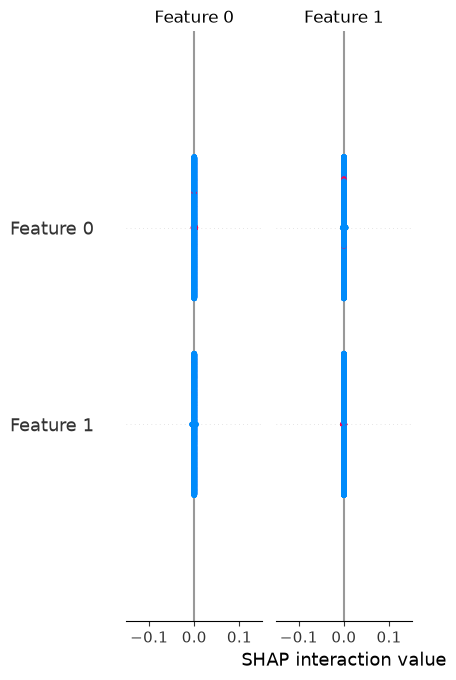

<Figure size 640x480 with 0 Axes>

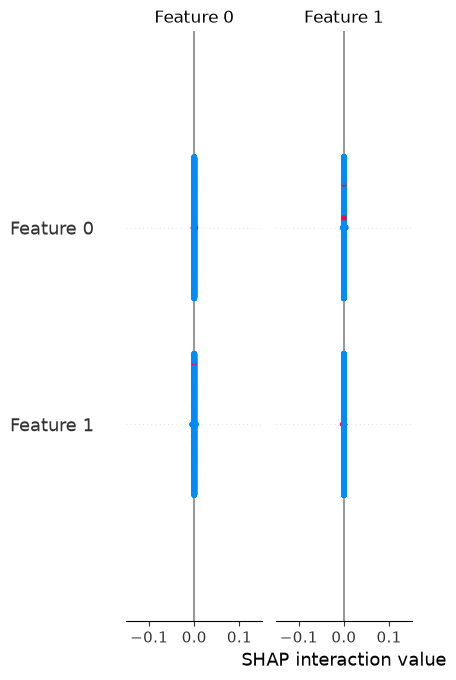

In [11]:
import shap
import matplotlib.pyplot as plt

noms_colonnes = preprocessor_rfc.get_feature_names_out()
X_test_rfc_df = pd.DataFrame(X_test_rfc, columns=noms_colonnes)

explainer = shap.TreeExplainer(best_rfc)
shap_values = explainer(X_test_rfc)

# Importance globale des facteurs de risque
plt.figure()
shap.summary_plot(shap_values, X_test_rfc, plot_type="bar")

# Graphique d'impact (Visualiser si une valeur haute augmente ou baisse le risque)
plt.figure()
shap.summary_plot(shap_values, X_test_rfc)

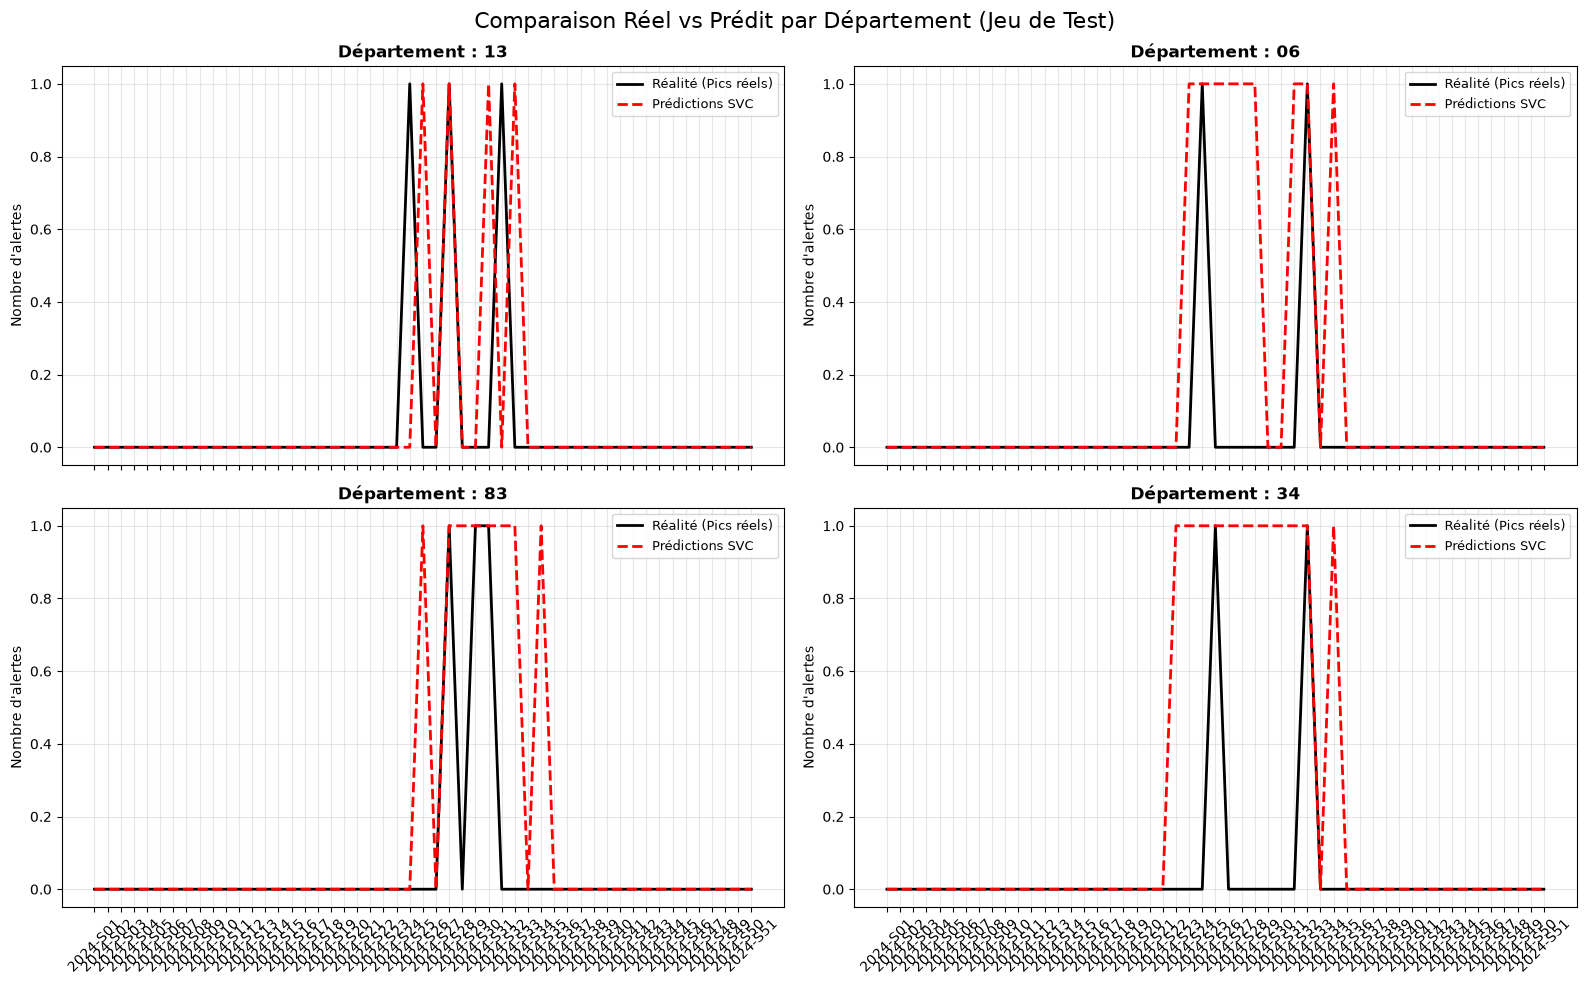

In [ ]:
# Copie et préparation des données de test
df_plot = df_test.copy()
df_plot['y_reel'] = y_test
df_plot['y_pred'] = y_pred_test

liste_depts = ['13', '06', '83', '34']

# Filtrer pour ne garder que ces 4 départements
df_plot_4depts = df_plot[df_plot['code_dept'].isin(liste_depts)]

# Création de la figure en grille (2x2)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(16, 10), sharex=True)
axes = axes.flatten()

for i, dept in enumerate(liste_depts):
    ax = axes[i]
    df_dept = df_plot_4depts[df_plot_4depts['code_dept'] == dept]
    
    # Agrégation par semaine pour ce département
    df_agg = df_dept.groupby('date_semaine')[['y_reel', 'y_pred']].sum().reset_index()
    
    # Tracé
    ax.plot(df_agg['date_semaine'], df_agg['y_reel'], label='Réalité (Pics réels)', color='black', linewidth=2)
    ax.plot(df_agg['date_semaine'], df_agg['y_pred'], label='Prédictions SVC', color='red', linestyle='--', linewidth=2)
    
    ax.set_title(f"Département : {dept}", fontsize=12, fontweight='bold')
    ax.set_ylabel("Nombre d'alertes", fontsize=10)
    ax.legend(loc='upper right', fontsize=9)
    ax.grid(True, alpha=0.3)
    ax.tick_params(axis='x', rotation=45)

plt.suptitle("Comparaison Réel vs Prédit par Département (Jeu de Test)", fontsize=16, y=0.98)
plt.tight_layout()
plt.show()